In [1]:
%load_ext autoreload

import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s') # NOTSET, DEBUG, INFO, WARN, ERROR, CRITICAL

import os
import numpy as np

os.environ["JAX_PLATFORM_NAME"] = "cpu"  # must be set before importing jax

import jax
import jax.numpy as jnp
from jax import vmap, jit, grad, jacfwd

import skewerjax as sjx

import matplotlib as mpl
from matplotlib.collections import LineCollection
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
plt.style.use('tableau-colorblind10')
font, rcnew = sjx.config.setup_matplotlib.matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)
%matplotlib widget

INFO:2026-05-09 15:17:04,416:jax._src.xla_bridge:752: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-05-09 15:17:04,416 - INFO - Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-05-09 15:17:04,781 - INFO - SkewerBundle class definition complete


In [2]:
# ================================================================
# Parameters

seed = 137 
N_samples = 512
Npix = 1024
L_box = 100

delta_v_list = [0.0, L_box/15] # [0.0, L_box/100, L_box/5]

# ================================================================
# Derived quantities

dv = L_box / Npix
v = np.arange(Npix) * dv

rng = np.random.default_rng(seed)

# ================================================================
# toy data generation

n_pairs = 2
sigma_list = [L_box / 1000, L_box / 1000]
amplitude_list = [10.0, 10.0]
gen = sjx.skewers.toy_skewers.ShiftedSpikeTauGenerator1D(
    Npix=Npix, L_box=L_box, delta_v_list=delta_v_list, sigma_list=sigma_list, amplitude_list=amplitude_list, n_pairs=n_pairs,
)
tau_fields = gen.sample(N_samples=N_samples, seed=seed)

# -------------------- compute fields -------------------- #
fields = {}
labels = []
for ii in range(tau_fields.shape[1]):
    _label = str(ii + 1)
    labels.append(_label)
    fields[_label] = np.exp(-tau_fields[:, ii])

In [3]:
overflux = sjx.skewers.skewers.DeltaFieldBuilder(fields).build()

In [4]:
stats = sjx.summary_stats.P1D_xi1D.OverfluxStatistics1D(overflux, dv)

stats.compute_p1d()
Pk_total_per_sample = stats.Pk_total_per_sample
Pk_total = stats.Pk_total
Pk_pair_per_sample = stats.Pk_pair_per_sample
Pk_pair = stats.Pk_pair
Pk_total_from_terms = stats.Pk_total_from_terms

stats.compute_xi1d()
xi_total_per_sample = stats.xi_total_per_sample
xi_total = stats.xi_total
xi_pair_per_sample = stats.xi_pair_per_sample
xi_pair = stats.xi_pair
xi_total_from_terms = stats.xi_total_from_terms

In [5]:
ordered_pairs = stats.ordered_pairs
k = stats.k
lags = stats.lags

lags_norm = lags / L_box
k_norm = k * L_box / (2.0 * np.pi)

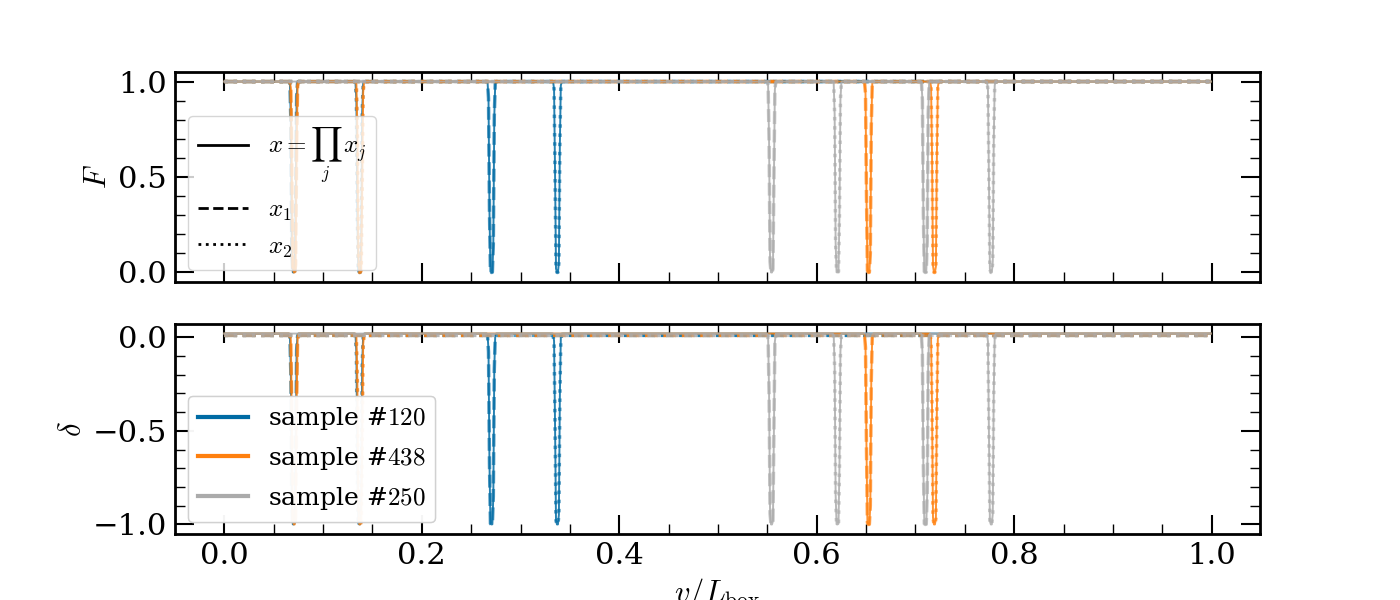

/home/dlopez/Documentos/0.profesional/Postdoc/USP/Projects/SkewerJAX/skewerjax/utils/plotting_tools_P1D_xi1D.py:616: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


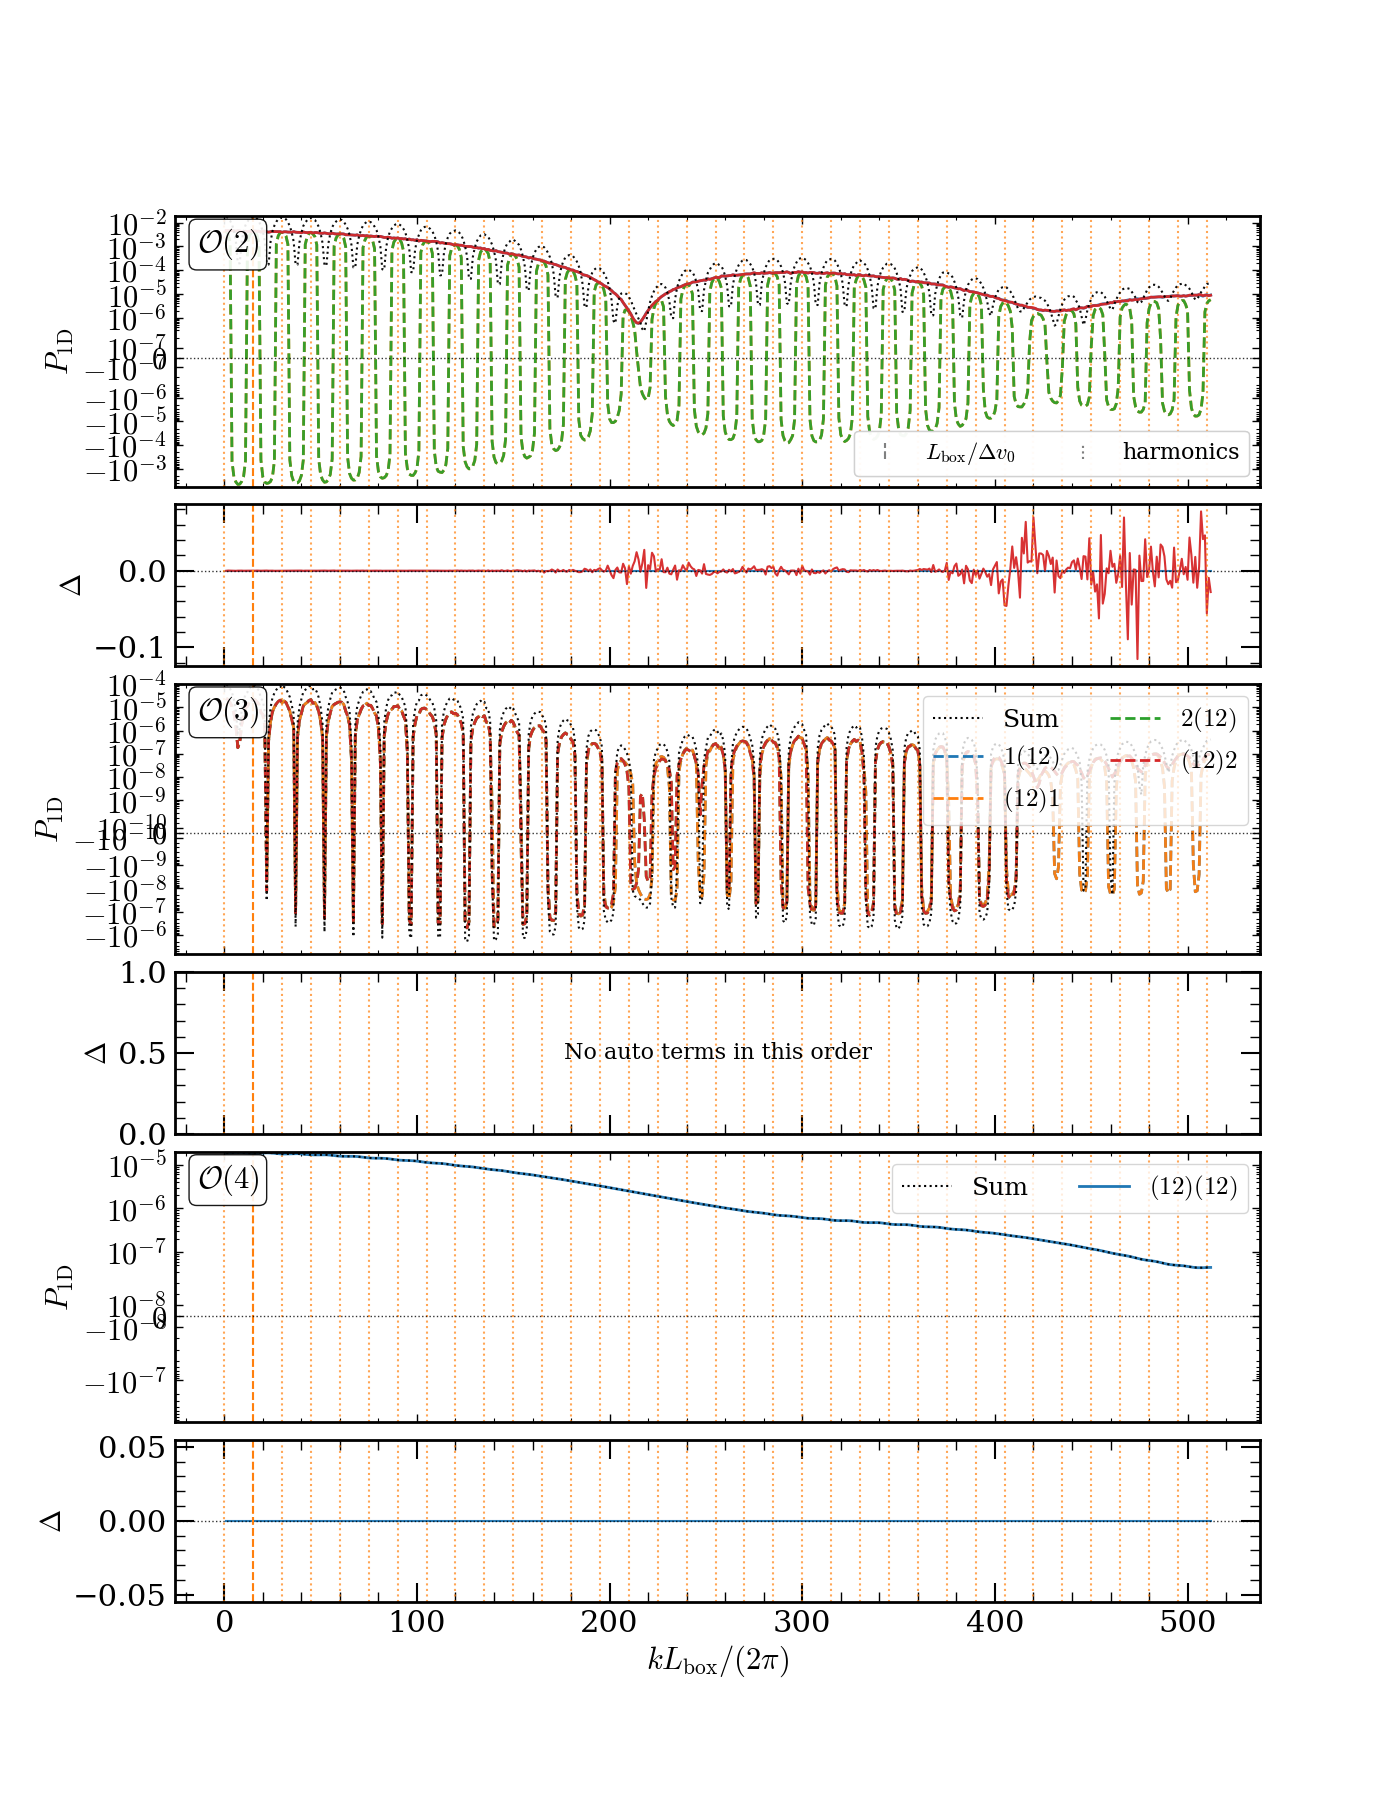

/home/dlopez/.miniconda3/envs/skewerjax/lib/python3.11/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/dlopez/.miniconda3/envs/skewerjax/lib/python3.11/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/home/dlopez/Documentos/0.profesional/Postdoc/USP/Projects/SkewerJAX/skewerjax/utils/plotting_tools_P1D_xi1D.py:767: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


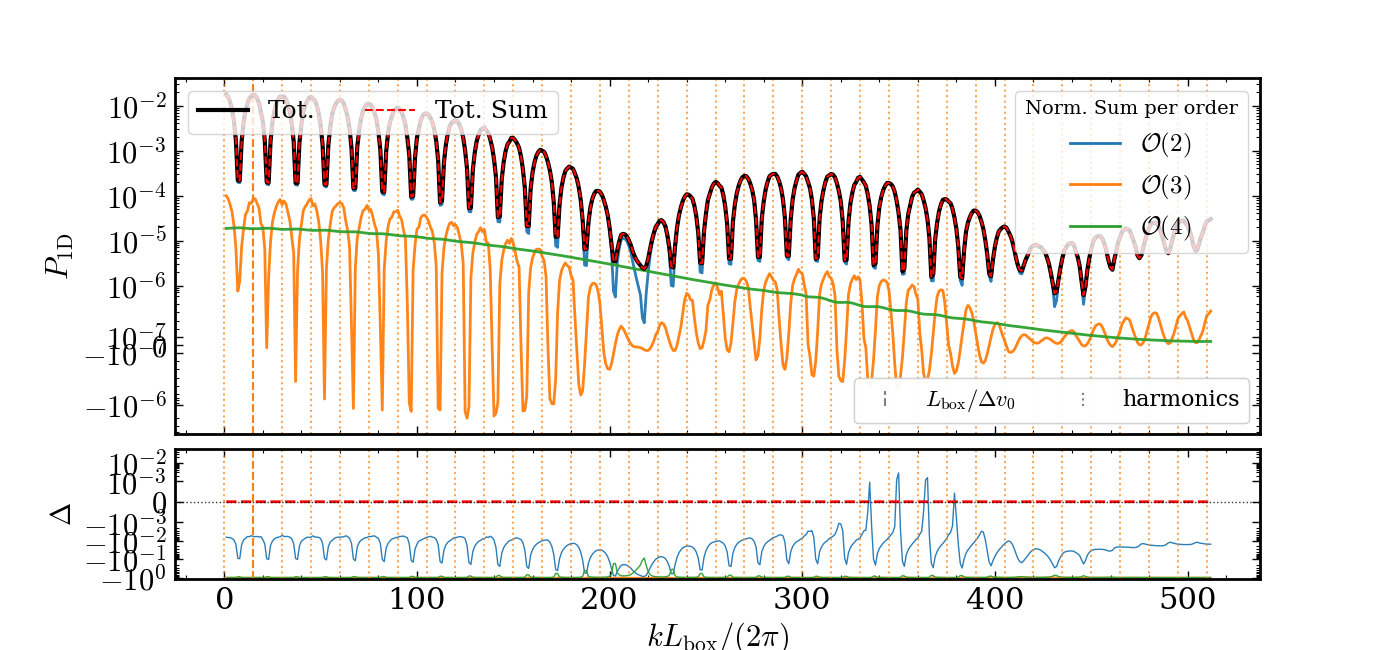

/home/dlopez/Documentos/0.profesional/Postdoc/USP/Projects/SkewerJAX/skewerjax/utils/plotting_tools_P1D_xi1D.py:956: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


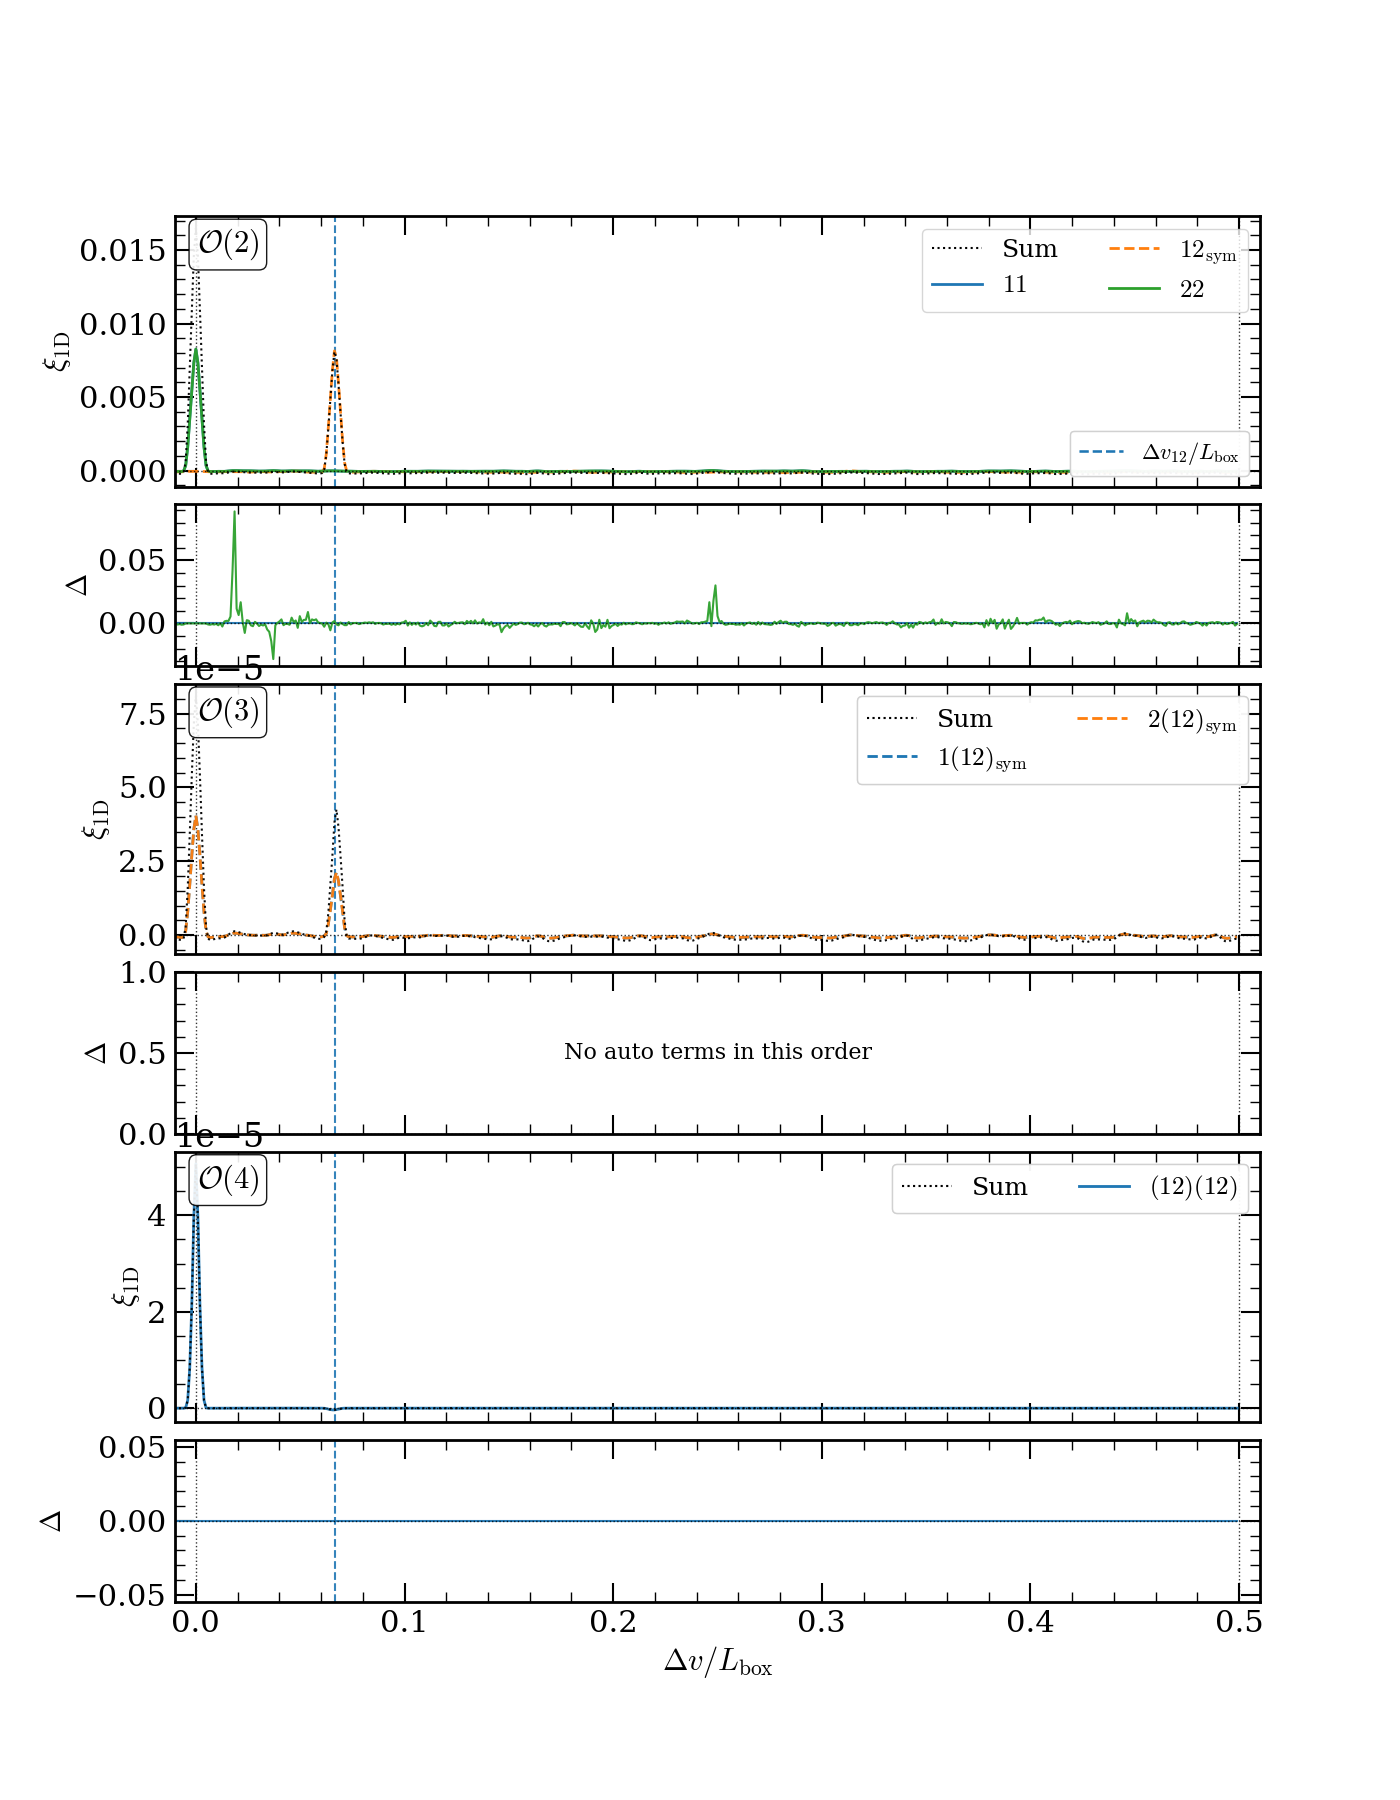

/home/dlopez/Documentos/0.profesional/Postdoc/USP/Projects/SkewerJAX/skewerjax/utils/plotting_tools_P1D_xi1D.py:1115: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


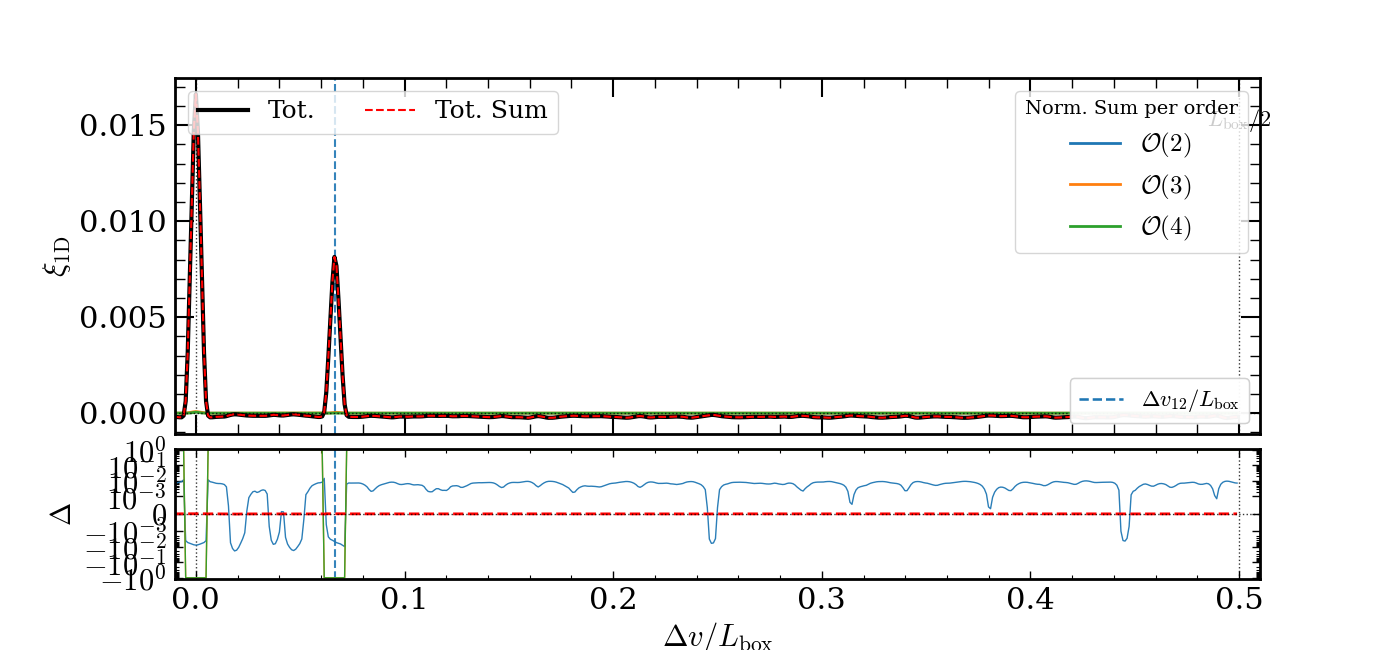

In [6]:
# ================================================================
# Plot fields 

idx = rng.choice(overflux.field_total.shape[0], size=3, replace=False)
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
linestyles = ["--", ":", "-.", (0, (3, 1, 1, 1)), (0, (5, 1))]

fig, axes = plt.subplots(figsize=(14, 6), ncols=1, nrows=2, sharex=True)
for j, i in enumerate(idx):
    c = colors[j % len(colors)]
    axes[0].plot(v / L_box, overflux.field_total[i], lw=1.4, alpha=0.85, color=c, ls="-")
    axes[1].plot(v / L_box, overflux.total[i], lw=1.4, alpha=0.85, color=c, ls="-")
    for m, label in enumerate(labels):
        ls = linestyles[m % len(linestyles)]
        axes[0].plot(v / L_box, fields[label][i], lw=2.5, alpha=0.65, color=c, ls=ls)
        axes[1].plot(v / L_box, overflux.delta_terms[label][i], lw=2.5, alpha=0.65, color=c, ls=ls)

axes[0].set_ylabel(r"$F$", fontsize=22)
axes[0].tick_params(axis="both", labelsize=22)
axes[1].set_xlabel(r"$v / L_\mathrm{box}$", fontsize=22)
axes[1].set_ylabel(r"$\delta$", fontsize=22)
axes[1].tick_params(axis="both", labelsize=22)

style_legend = [Line2D([0], [0], color="k", lw=2.0, ls="-", label=rf"$x=\prod_j\, x_j$")]
for m, label in enumerate(labels):
    ls = linestyles[m % len(linestyles)]
    style_legend.append(Line2D([0], [0], color="k", lw=2.0, ls=ls, label=rf"$x_{label}$"))
axes[0].legend(handles=style_legend, fontsize=18, loc="lower left")

sample_legend = [Line2D([0], [0], color=colors[j % len(colors)], lw=3.0, ls="-", label=fr"sample #${i}$") for j, i in enumerate(idx)]
leg2 = axes[1].legend(handles=sample_legend, fontsize=18, loc="lower left")
axes[1].add_artist(leg2)

plt.show()

# ================================================================
# Plot summary statistics and decomposition

fig, axes, axes_res, order_sum_dict = sjx.utils.plotting_tools_P1D_xi1D.plot_p1d_by_order(
    ordered_pairs=ordered_pairs, Pk_pair=Pk_pair, k_norm=k_norm, delta_v_list=delta_v_list, L_box=L_box, Npix=Npix,
    tolerance_threshold=1e-6,
    residual_mode="auto_reference",
    show_harmonics=True,
    use_symlog_main=True,
    use_symlog_residual=False,
    symlog_linscale=1.0,
    symlog_label_minor=False,
    symlog_sci_cutoff=1e-2,
    legend_ncol_terms=2,
    xlabel=r"$kL_\mathrm{box}/(2\pi)$", ylabel=r"$P_{\rm 1D}$", residual_ylabel=r"$\Delta$",
)

fig, (ax, ax_res), order_sum_dict = sjx.utils.plotting_tools_P1D_xi1D.plot_p1d_total_recovery(
    Pk_total=Pk_total, Pk_total_from_terms=Pk_total_from_terms, Pk_pair=Pk_pair, k_norm=k_norm, delta_v_list=delta_v_list, L_box=L_box, Npix=Npix,
    ordered_pairs=ordered_pairs,
    show_order_sums=True,
    show_order_sum_residuals=True,
    use_symlog_main=True,
    use_symlog_residual=True,
)

fig, axes, axes_res, xi_order_sum_dict, xi_order_sum_plot_dict = sjx.utils.plotting_tools_P1D_xi1D.plot_xi_by_order(
    ordered_pairs=ordered_pairs, xi_pair=xi_pair, lags_norm=lags_norm, delta_v_list=delta_v_list, L_box=L_box,
    tolerance_threshold=1e-6,
    residual_mode="auto_reference",
    xlim=(-0.01, 0.51),
    show_delta_v_diff_lines=True,
    use_symlog_main=False,
    use_symlog_residual=False,
    symlog_linscale=1.0,
    symlog_base=10,
    symlog_label_minor=False,
    symlog_sci_cutoff=1e-2,
    show_order_badge=True,
    legend_ncol_terms=2,
    xlabel=r"$\Delta v / L_\mathrm{box}$", ylabel=r"$\xi_{\rm 1D}$", residual_ylabel=r"$\Delta$",
)

fig, (ax, ax_res), xi_order_sum_dict, xi_order_sum_plot_dict = sjx.utils.plotting_tools_P1D_xi1D.plot_xi_total_recovery(
    xi_total=xi_total, xi_total_from_terms=xi_total_from_terms, xi_pair=xi_pair, lags_norm=lags_norm, delta_v_list=delta_v_list, L_box=L_box, ordered_pairs=ordered_pairs,
    xlim=(-0.01, 0.51),
    show_order_sums=True,
    show_order_sum_residuals=True,
    show_delta_v_diff_lines=True,
    annotate_half_line=True,
    half_line_text=r"$L_\mathrm{box}/2$",
    use_symlog_main=False,
    use_symlog_residual=True,
    main_symlog_linthresh=None,
    symlog_linscale=1.0,
    symlog_base=10,
    symlog_sci_cutoff=1e-2,
    xlabel=r"$\Delta v / L_\mathrm{box}$", ylabel=r"$\xi_{\rm 1D}$", residual_ylabel=r"$\Delta$",
)